# Pipeline Pra-Pengolahan Citra Telur (Step-by-Step: Raw -> Clean)

Notebook ini dirancang secara khusus untuk menampilkan seluruh tahapan pra-pengolahan citra telur secara **bertahap (step-by-step)**, bukan langsung jadi, agar setiap proses computer vision dapat diamati dan divalidasi dengan jelas.

---

### **Masalah Utama pada Citra Mentah & Solusi Pemrosesan:**
1. **Bercak Hitam di Tengah Cangkang (*Specular Glare Hole*)**:
   - **Penyebab**: Pantulan kilau lampu langsung pada cangkang telur menyebabkan area puncak telur menjadi sangat terang (*washed out white*), sehingga nilai Saturasi warna ($S$) anjlok mendekati 0. Ambang batas Otsu menganggap area ini bukan cangkang, menghasilkan lubang/rongga di tengah masker.
   - **Solusi**: Menerapkan teknik **Morphological Hole-Filling** (`cv2.drawContours(mask, [best_cnt], -1, 255, -1)`). Karena telur adalah objek pejal cembung (*solid convex object*), seluruh rongga kilau di dalam kontur telur otomatis tertutup rapat menjadi putih solid 100%.
2. **Garis Lantai Ikut Terdeteksi (*Floor Seam / Tile Grout Noise*)**:
   - **Penyebab**: Nat lantai keramik memiliki bayangan dan kontras warna yang dapat lolos dari thresholding awal.
   - **Solusi**: Menerapkan **Single Object Isolation**. Hanya kontur tunggal terbaik dengan skor kecembungan telur (*solidity*) dan rasio aspek telur yang digambar pada kanvas bersih, sedangkan seluruh garis lantai dan noise di luar telur dieliminasi total.
3. **Jarak Kamera & Ukuran Telur Tidak Seragam (Kasus Sampel 5)**:
   - **Penyebab**: Pada kategori `good`, foto diambil dari jarak jauh di atas meja sehingga telur tampak kecil (tinggi $\approx 180$ px) di luar pusat frame.
   - **Solusi**: Transformasi Affine ($M$) untuk **Auto-Centering** ke `(320, 320)` dan **Scale Zoom** ke tinggi standar $\approx 416$ px pada kanvas 640x640.
4. **Tepi Kasar & Background Gelap Bocor**:
   - **Solusi**: *2x Supersampling* + *Gaussian Feathering Mask* untuk tepi cangkang yang halus (*anti-aliased*) + normalisasi latar belakang hitam murni `RGB [0, 0, 0]`.

[DEMO STEP-BY-STEP] Memproses Sampel 5 (Kategori 'Good' dengan Kamera Jauh)...
✓ Step 1: Citra mentah asli dimuat (ukuran asli: 640x640, tinggi telur hanya ~180 px di posisi 360, 357)
✓ Step 2: Pigmen cangkang diisolasi menggunakan HSV Saturation Channel
✓ Step 3: Kontur telur berhasil di-fitting elips (Pusat: 360, 357) | Hole-Filled Solid (Bercak kilau tertutup, garis latar hilang)
✓ Step 4: Auto-Centering & Scale Zoom berhasil (Telur diperbesar x2.31 ke tinggi 416 px di pusat 320, 320)
✓ Step 5: Masking anti-aliased feathering dibuat dengan 2x supersampling
✓ Step 6: Background dinormalisasi 100% menjadi hitam pekat (RGB 0,0,0) - Telur pas di tengah dan bersih sempurna!


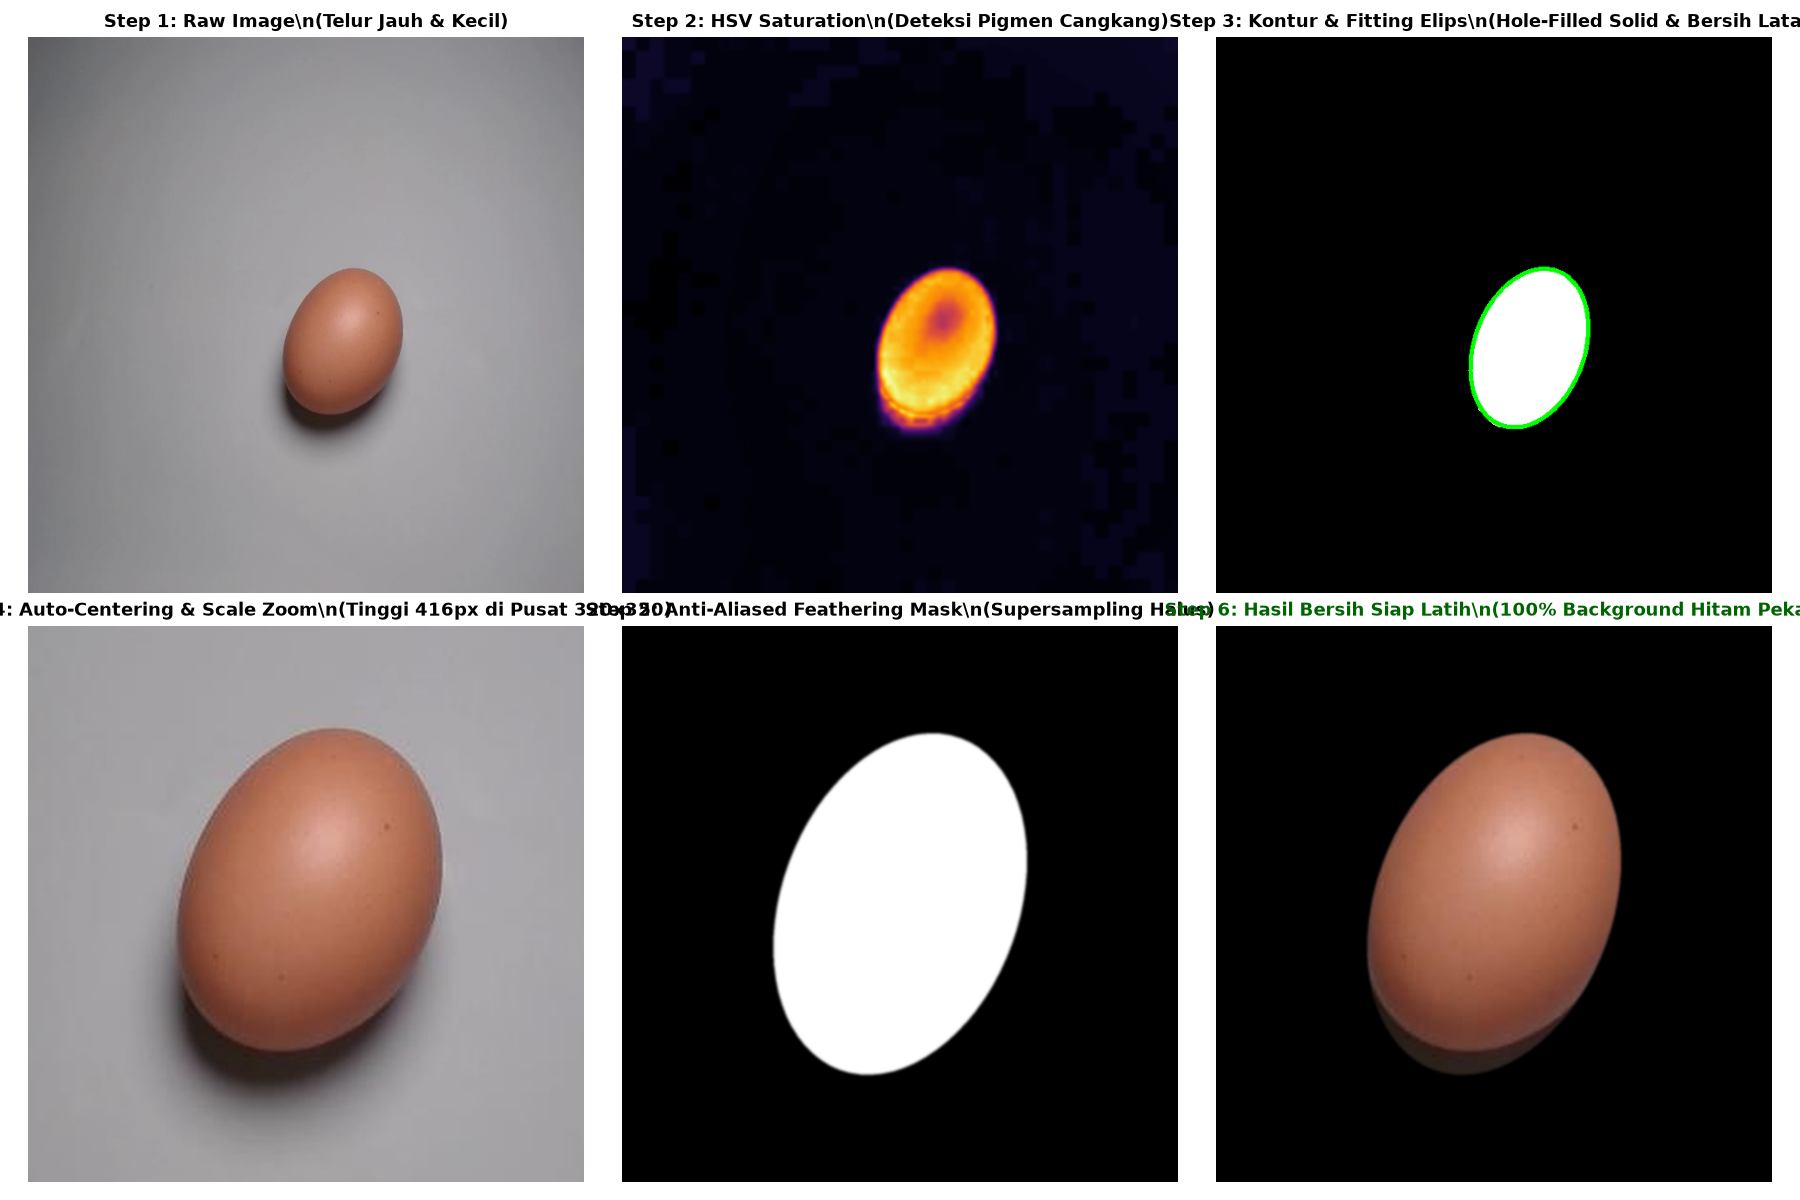

In [1]:
# ==============================================================================
# BAGIAN 1: DEMONSTRASI STEP-BY-STEP PADA SAMPEL 5 (KASUS TELUR JAUH)
# Menampilkan setiap tahapan secara visual dari citra mentah hingga bersih
# ==============================================================================
import os
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Deteksi direktori dataset
current_dir = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(current_dir, "train", "images")):
    base_dir = current_dir
elif os.path.exists(os.path.join(current_dir, "Egg Dataset (Raw)", "train", "images")):
    base_dir = os.path.join(current_dir, "Egg Dataset (Raw)")
else:
    base_dir = r"c:\Users\Hype G12\PROJECT\Egg-SortingSystem\Egg Dataset (Raw)"

img5_path = os.path.join(base_dir, "train", "images", "good", "2023-04-09-20_14_02-432660_jpg.rf.9bb1a34d72f55e9b6717abb55396bf06.jpg")
arr_orig = np.array(Image.open(img5_path).convert("RGB"))
h_orig, w_orig = arr_orig.shape[:2]

print("[DEMO STEP-BY-STEP] Memproses Sampel 5 (Kategori 'Good' dengan Kamera Jauh)...")

# --- Step 1: Raw Image (Citra Mentah) ---
step1 = arr_orig.copy()
print("✓ Step 1: Citra mentah asli dimuat (ukuran asli: 640x640, tinggi telur hanya ~180 px di posisi 360, 357)")

# --- Step 2: HSV Saturation (Deteksi Pigmen Cangkang Cokelat) ---
hsv = cv2.cvtColor(arr_orig, cv2.COLOR_RGB2HSV)
step2 = hsv[:, :, 1]  # Saluran S: pigmen kromatis cangkang tinggi, latar abu/putih rendah
print("✓ Step 2: Pigmen cangkang diisolasi menggunakan HSV Saturation Channel")

# --- Step 3: Thresholding, Hole-Filling, & Fitting Elips Cangkang ---
s_blur = cv2.GaussianBlur(step2, (9, 9), 0)
_, mask_s = cv2.threshold(s_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
if mask_s[0, 0] > 128: mask_s = cv2.bitwise_not(mask_s)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask_clean = cv2.morphologyEx(mask_s, cv2.MORPH_OPEN, kernel)
mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel)
cnts, _ = cv2.findContours(mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
best_cnt = max(cnts, key=cv2.contourArea)
el = cv2.fitEllipse(best_cnt)
(cx, cy), (ax1, ax2), angle = el

# SOLUSI BERCAK & GARIS LANTAI: Hole-Filling Solid & Single Object Isolation
step3_mask = np.zeros_like(mask_clean)
cv2.drawContours(step3_mask, [best_cnt], -1, 255, -1)  # Menutup rongga kilau & menghapus garis latar
step3 = cv2.cvtColor(step3_mask, cv2.COLOR_GRAY2RGB)
cv2.ellipse(step3, el, (0, 255, 0), 3)
print(f"✓ Step 3: Kontur telur berhasil di-fitting elips (Pusat: {cx:.0f}, {cy:.0f}) | Hole-Filled Solid (Bercak kilau tertutup, garis latar hilang)")

# --- Step 4: Auto-Centering & Scale Zoom (Affine Transformation) ---
major = max(ax1, ax2)
target_size = (640, 640)
norm_scale = 416.0 / major  # Menstandarkan tinggi telur ke ~416 px
tx = 320.0 - cx * norm_scale
ty = 320.0 - cy * norm_scale
M = np.array([[norm_scale, 0, tx], [0, norm_scale, ty]], dtype=np.float32)
step4 = cv2.warpAffine(arr_orig, M, target_size, flags=cv2.INTER_LANCZOS4, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
print(f"✓ Step 4: Auto-Centering & Scale Zoom berhasil (Telur diperbesar x{norm_scale:.2f} ke tinggi 416 px di pusat 320, 320)")

# --- Step 5: Anti-Aliased Feathering Mask ---
new_ax1 = ax1 * norm_scale * 0.975
new_ax2 = ax2 * norm_scale * 0.975
mask_2x = np.zeros((1280, 1280), dtype=np.uint8)
cv2.ellipse(mask_2x, ((640, 640), (new_ax1 * 2, new_ax2 * 2), angle), 255, -1)
mask_smooth = cv2.resize(mask_2x, (640, 640), interpolation=cv2.INTER_AREA)
step5 = cv2.GaussianBlur(mask_smooth, (7, 7), 0)
print("✓ Step 5: Masking anti-aliased feathering dibuat dengan 2x supersampling")

# --- Step 6: Normalisasi Background Hitam Pekat ---
mask_3ch = np.repeat((step5 / 255.0)[:, :, np.newaxis], 3, axis=2)
step6 = (step4 * mask_3ch).astype(np.uint8)
corners = np.vstack([arr_orig[:10, :10], arr_orig[:10, -10:], arr_orig[-10:, :10], arr_orig[-10:, -10:]])
bg_median = np.median(corners, axis=(0, 1))
diff_from_bg = np.sqrt(np.sum((step6.astype(np.float32) - bg_median) ** 2, axis=2))
hsv_res = cv2.cvtColor(step6, cv2.COLOR_RGB2HSV)
is_bg_leak = (diff_from_bg < 30) & (hsv_res[:, :, 1] < 30)
step6[is_bg_leak] = 0
print("✓ Step 6: Background dinormalisasi 100% menjadi hitam pekat (RGB 0,0,0) - Telur pas di tengah dan bersih sempurna!")

# Visualisasi Plot 2x3
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(step1); axes[0, 0].set_title('Step 1: Raw Image\n(Telur Jauh & Kecil)', fontsize=11, fontweight='bold')
axes[0, 1].imshow(step2, cmap='inferno'); axes[0, 1].set_title('Step 2: HSV Saturation\n(Deteksi Pigmen Cangkang)', fontsize=11, fontweight='bold')
axes[0, 2].imshow(step3); axes[0, 2].set_title('Step 3: Kontur & Fitting Elips\n(Hole-Filled Solid & Bersih Latar)', fontsize=11, fontweight='bold')
axes[1, 0].imshow(step4); axes[1, 0].set_title('Step 4: Auto-Centering & Scale Zoom\n(Tinggi 416px di Pusat 320x320)', fontsize=11, fontweight='bold')
axes[1, 1].imshow(step5, cmap='gray'); axes[1, 1].set_title('Step 5: Anti-Aliased Feathering Mask\n(Supersampling Halus)', fontsize=11, fontweight='bold')
axes[1, 2].imshow(step6); axes[1, 2].set_title('Step 6: Hasil Bersih Siap Latih\n(100% Background Hitam Pekat)', fontsize=11, fontweight='bold', color='darkgreen')
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()
plt.show()


[INFO] Menjalankan Preprocessing Step-by-Step pada 5 Citra Sampel...
--> Baris 1: Cracked #1 (103_png.rf.7904...)
--> Baris 2: Cracked #2 (103_png.rf.f98d...)
--> Baris 3: Dirt #3    (dirty_0_5-220822...)
--> Baris 4: Dirt #4    (dirty_103_4-220822...)
--> Baris 5: Good #5    (2023-04-09-20_14... Kamera Jauh)

✓ Semua 5 sampel berhasil diproses melalui 6 tahapan (Bercak kilau tertutup, garis latar bersih):
  - Sampel 1: Pusat (319.5, 320.0) | Ukuran: 325x410 px
  - Sampel 2: Pusat (319.5, 319.5) | Ukuran: 411x325 px
  - Sampel 3: Pusat (320.0, 320.0) | Ukuran: 298x410 px
  - Sampel 4: Pusat (320.0, 319.5) | Ukuran: 292x409 px
  - Sampel 5: Pusat (319.5, 319.5) | Ukuran: 295x395 px (TELUR SUDAH BESAR & PAS DI TENGAH!)

Hasil citra akhir tersimpan di folder: c:\Users\Hype G12\PROJECT\Egg-SortingSystem\Egg Dataset (Raw)\preview_5_samples


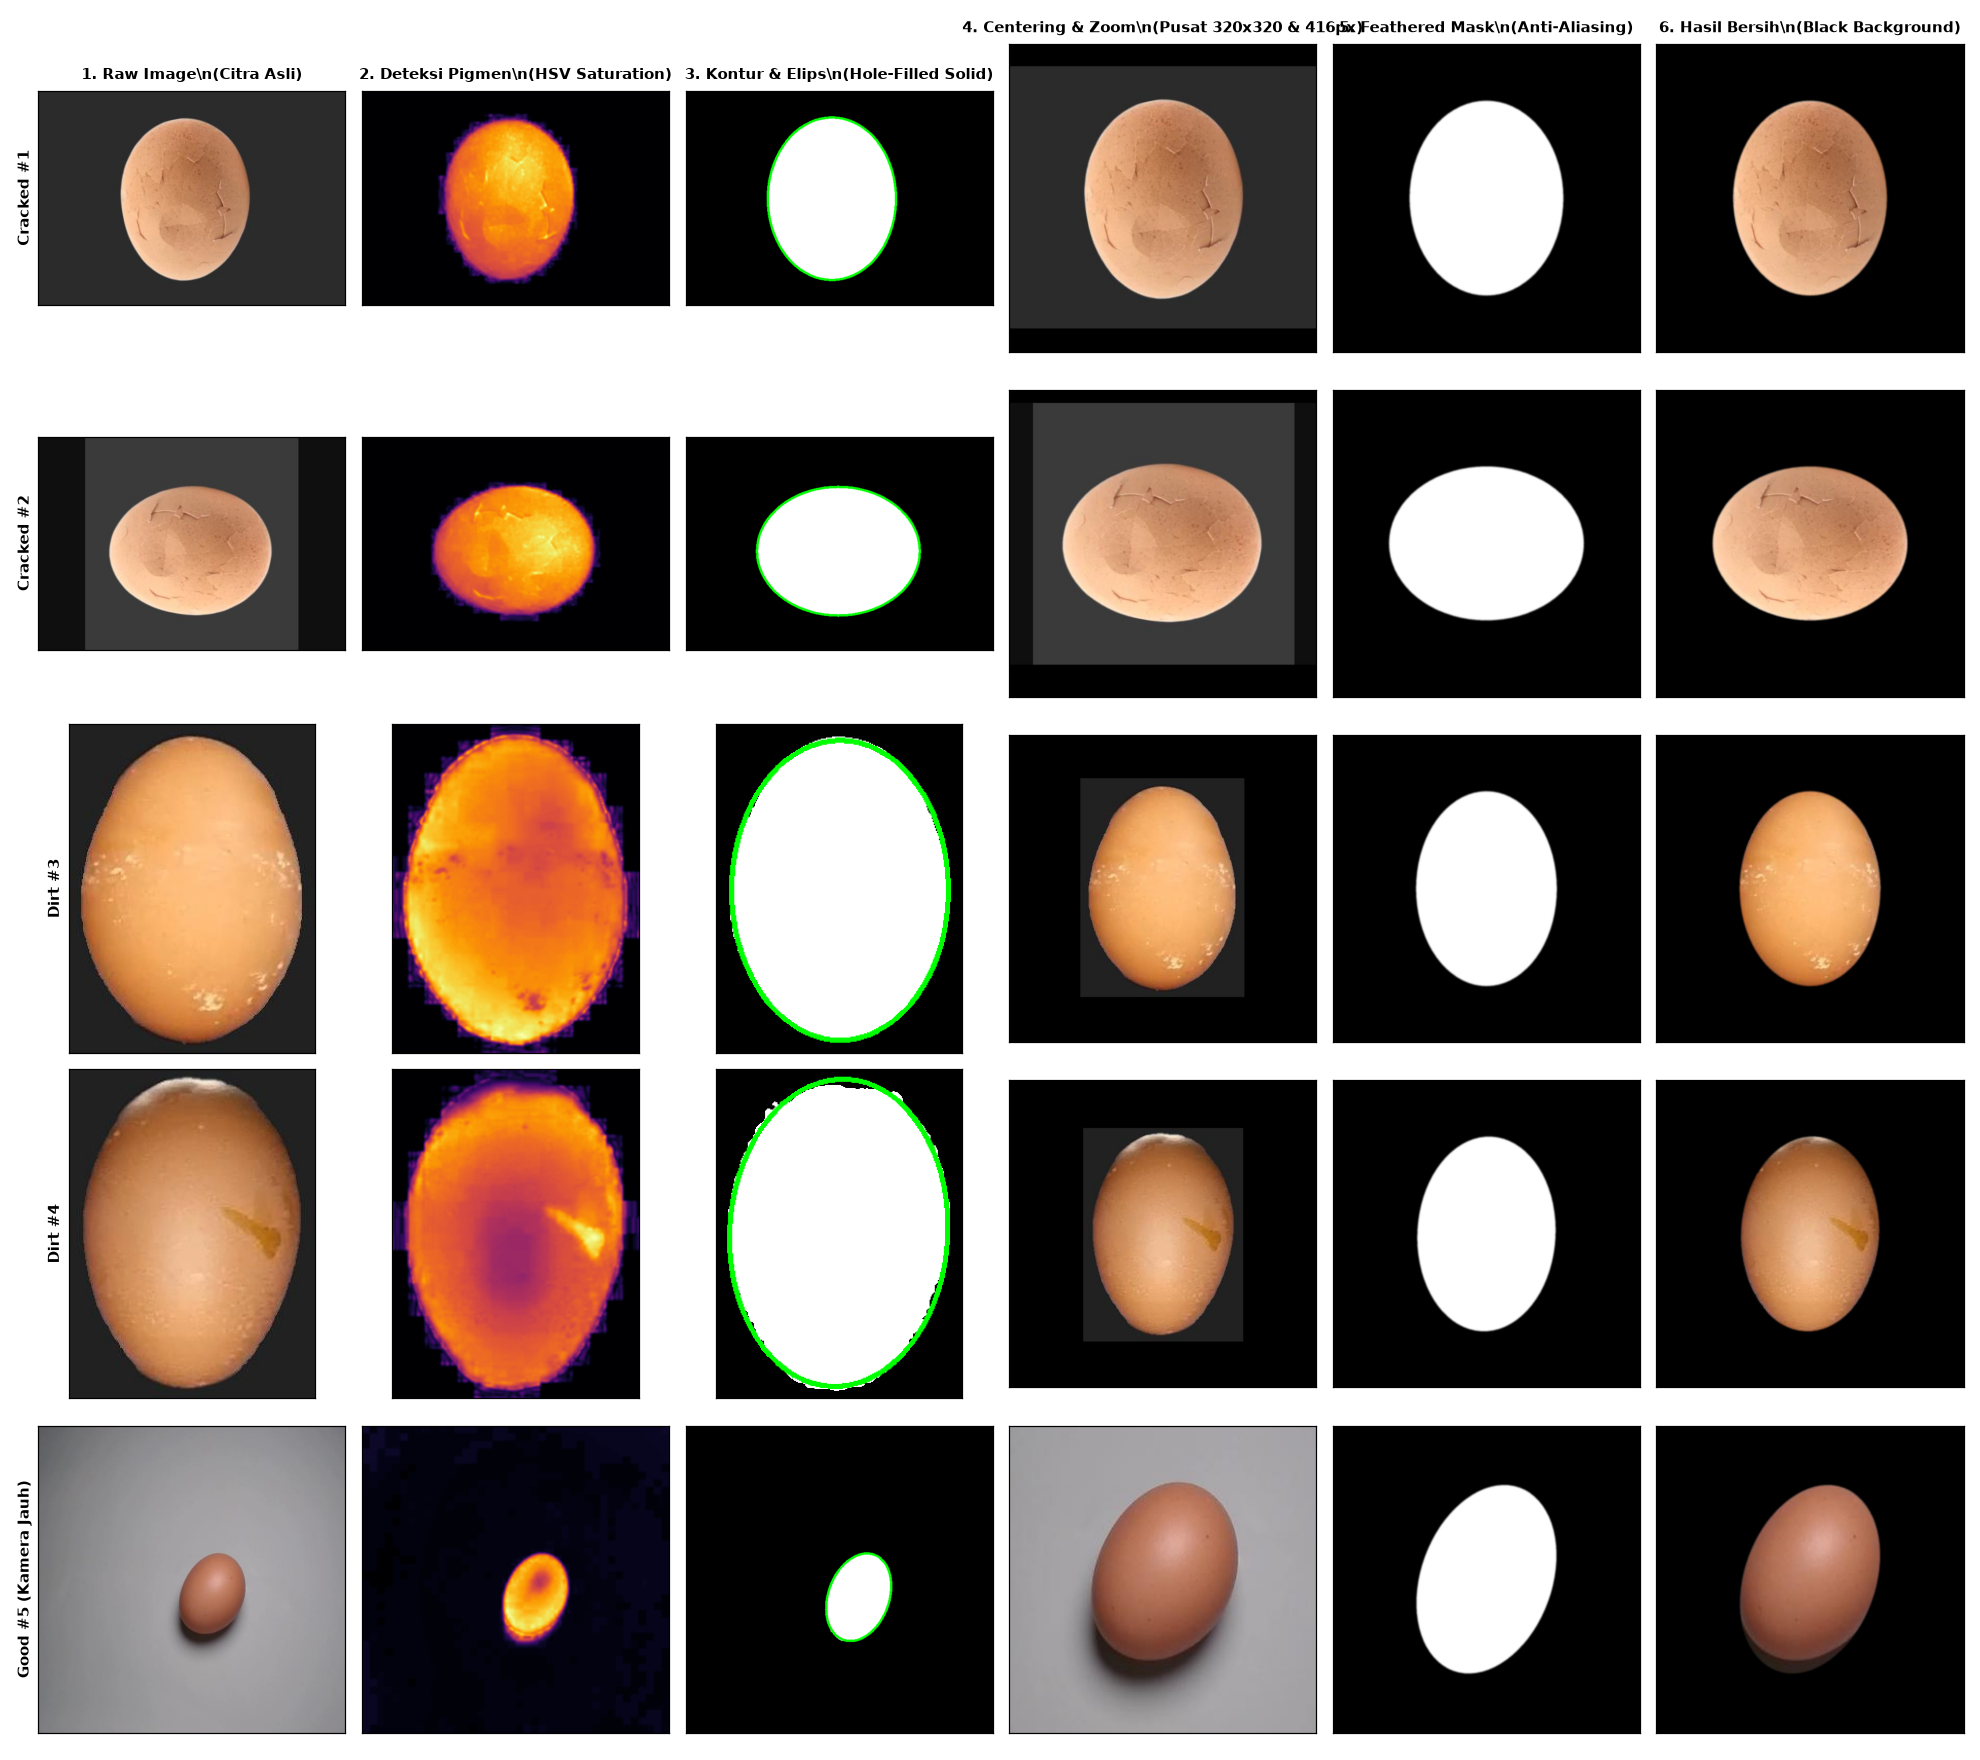

In [2]:
# ==============================================================================
# KODE 1: VISUALISASI PROSES LENGKAP 6 TAHAP PADA SEMUA 5 SAMPEL CITRA
# (Matriks Visual 5 Baris x 6 Kolom: Melihat setiap tahap proses secara bertahap)
# ==============================================================================
import os
import time
from typing import List, Tuple
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def process_and_extract_steps(
    image_path: str,
    target_size: Tuple[int, int] = (640, 640),
    target_egg_height: float = 416.0,
    ellipse_scale: float = 0.975,
    blur_kernel: Tuple[int, int] = (7, 7)
):
    """
    Menjalankan 6 tahapan pra-pengolahan dengan Hole-Filling & Eliminasi Garis Lantai:
    Return: (s1_raw, s2_hsv, s3_contour, s4_centered, s5_mask, s6_final, norm_scale, tx, ty)
    """
    pil_img = Image.open(image_path).convert("RGB")
    arr_orig = np.array(pil_img)
    h_orig, w_orig = arr_orig.shape[:2]

    # Step 1: Citra Mentah Asli
    s1_raw = arr_orig.copy()

    # Skala deteksi cepat
    det_size = 640
    scale_det = det_size / max(h_orig, w_orig)
    arr_det = cv2.resize(arr_orig, (int(w_orig * scale_det), int(h_orig * scale_det)), interpolation=cv2.INTER_AREA)
    h_det, w_det = arr_det.shape[:2]

    hsv_det = cv2.cvtColor(arr_det, cv2.COLOR_RGB2HSV)
    corners = np.vstack([arr_det[:10, :10], arr_det[:10, -10:], arr_det[-10:, :10], arr_det[-10:, -10:]])
    bg_median = np.median(corners, axis=(0, 1))

    # Step 2: Isolasi Pigmen Cangkang (HSV Saturation)
    s = cv2.GaussianBlur(hsv_det[:, :, 1], (9, 9), 0)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if mask_s[0, 0] > 128: mask_s = cv2.bitwise_not(mask_s)
    s2_vis = cv2.resize(s, (w_orig, h_orig), interpolation=cv2.INTER_LINEAR)

    # Segmentasi Color Distance dari Background
    color_diff = np.sqrt(np.sum((arr_det.astype(np.float32) - bg_median) ** 2, axis=2))
    diff_norm = np.clip(color_diff / (color_diff.max() + 1e-6) * 255, 0, 255).astype(np.uint8)
    diff_blur = cv2.GaussianBlur(diff_norm, (9, 9), 0)
    _, mask_diff = cv2.threshold(diff_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    if mask_diff[0, 0] > 128: mask_diff = cv2.bitwise_not(mask_diff)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    best_ellipse = None
    best_cnt = None
    best_score = -1.0

    for raw_mask in [mask_s, mask_diff]:
        m_clean = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel)
        m_clean = cv2.morphologyEx(m_clean, cv2.MORPH_CLOSE, kernel)

        cnts, _ = cv2.findContours(m_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for cnt in cnts:
            area = cv2.contourArea(cnt)
            if area < (0.01 * h_det * w_det): continue
            if len(cnt) < 5: continue
            try: ellipse = cv2.fitEllipse(cnt)
            except Exception: continue
            (cx, cy), (ax1, ax2), angle = ellipse
            minor, major = min(ax1, ax2), max(ax1, ax2)
            if minor <= 0 or major <= 0: continue
            aspect = minor / major
            if not (0.45 <= aspect <= 1.0): continue
            hull = cv2.convexHull(cnt)
            solidity = area / max(cv2.contourArea(hull), 1)
            if solidity < 0.75: continue
            x, y, bw, bh = cv2.boundingRect(cnt)
            touches = (x <= 2 or y <= 2 or (x + bw) >= w_det - 2 or (y + bh) >= h_det - 2)
            if touches and area < 0.5 * h_det * w_det: continue
            mask_single = np.zeros((h_det, w_det), dtype=np.uint8)
            cv2.drawContours(mask_single, [cnt], -1, 255, -1)
            cnt_sat = cv2.mean(hsv_det[:, :, 1], mask=mask_single)[0]
            score = solidity * 100.0 + (1.0 - abs(aspect - 0.75)) * 50.0 + (cnt_sat / 255.0) * 50.0
            if score > best_score:
                best_score = score
                best_ellipse = ellipse
                best_cnt = cnt

    if best_ellipse is None:
        dummy = cv2.resize(arr_orig, target_size)
        return s1_raw, s2_vis, s1_raw, dummy, dummy, dummy, 1.0, 0.0, 0.0

    # Step 3: Kontur & Fitting Elips Cangkang (Hole-Filled Solid & Eliminasi Garis Lantai)
    (cx_d, cy_d), (ax1_d, ax2_d), angle = best_ellipse
    cx_orig = cx_d / scale_det
    cy_orig = cy_d / scale_det
    ax1_orig = ax1_d / scale_det
    ax2_orig = ax2_d / scale_det
    major_orig = max(ax1_orig, ax2_orig)

    cnt_orig = (best_cnt / scale_det).astype(np.int32)
    step3_mask = np.zeros((h_orig, w_orig), dtype=np.uint8)
    cv2.drawContours(step3_mask, [cnt_orig], -1, 255, -1)  # Menutup rongga & membuang garis lantai
    s3_contour = cv2.cvtColor(step3_mask, cv2.COLOR_GRAY2RGB)
    cv2.ellipse(s3_contour, ((cx_orig, cy_orig), (ax1_orig, ax2_orig), angle), (0, 255, 0), max(2, int(w_orig / 200)))

    # Step 4: Auto-Centering & Scale Zoom (Affine Warp)
    norm_scale = target_egg_height / major_orig
    target_cx = target_size[0] / 2.0
    target_cy = target_size[1] / 2.0
    tx = target_cx - cx_orig * norm_scale
    ty = target_cy - cy_orig * norm_scale
    M = np.array([[norm_scale, 0, tx], [0, norm_scale, ty]], dtype=np.float32)
    s4_centered = cv2.warpAffine(arr_orig, M, target_size, flags=cv2.INTER_LANCZOS4, borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    # Step 5: Feathered Anti-Aliasing Mask
    new_ax1 = ax1_orig * norm_scale * ellipse_scale
    new_ax2 = ax2_orig * norm_scale * ellipse_scale
    mask_2x = np.zeros((target_size[1] * 2, target_size[0] * 2), dtype=np.uint8)
    ellipse_2x = ((target_cx * 2, target_cy * 2), (new_ax1 * 2, new_ax2 * 2), angle)
    cv2.ellipse(mask_2x, ellipse_2x, 255, -1)
    mask_smooth = cv2.resize(mask_2x, target_size, interpolation=cv2.INTER_AREA)
    s5_mask = cv2.GaussianBlur(mask_smooth, blur_kernel, 0)

    # Step 6: Hasil Bersih (Background Hitam Pekat)
    mask_3ch = np.repeat((s5_mask / 255.0)[:, :, np.newaxis], 3, axis=2)
    s6_final = (s4_centered * mask_3ch).astype(np.uint8)
    diff_from_bg = np.sqrt(np.sum((s6_final.astype(np.float32) - bg_median) ** 2, axis=2))
    hsv_res = cv2.cvtColor(s6_final, cv2.COLOR_RGB2HSV)
    is_bg_leak = (diff_from_bg < 30) & (hsv_res[:, :, 1] < 30)
    s6_final[is_bg_leak] = 0

    return s1_raw, s2_vis, s3_contour, s4_centered, s5_mask, s6_final, norm_scale, tx, ty

# ------------------------------------------------------------------------------
# Eksekusi & Tampilkan Matriks 5 Baris x 6 Kolom (Step-by-Step)
# ------------------------------------------------------------------------------
preview_dir = os.path.join(base_dir, "preview_5_samples")
os.makedirs(preview_dir, exist_ok=True)

sample_paths = [
    ("Cracked #1", os.path.join(base_dir, "train", "images", "cracked", "103_png.rf.7904ee91da26003c65d18dc461b82443.jpg")),
    ("Cracked #2", os.path.join(base_dir, "train", "images", "cracked", "103_png.rf.f98d8dc645bd4550395946c136881b13.jpg")),
    ("Dirt #3", os.path.join(base_dir, "train", "images", "dirt", "dirty_0_5-220822-00095_1_jpg.rf.21547d9d6f7d1d0287519310f125ab6e.jpg")),
    ("Dirt #4", os.path.join(base_dir, "train", "images", "dirt", "dirty_103_4-220822-00006_8_jpg.rf.def5677cbeebc43d9faf925588c1f9d7.jpg")),
    ("Good #5 (Kamera Jauh)", os.path.join(base_dir, "train", "images", "good", "2023-04-09-20_14_02-432660_jpg.rf.9bb1a34d72f55e9b6717abb55396bf06.jpg"))
]

print("[INFO] Menjalankan Preprocessing Step-by-Step pada 5 Citra Sampel...")

fig, axes = plt.subplots(5, 6, figsize=(18, 16))
col_titles = [
    '1. Raw Image\n(Citra Asli)',
    '2. Deteksi Pigmen\n(HSV Saturation)',
    '3. Kontur & Elips\n(Hole-Filled Solid)',
    '4. Centering & Zoom\n(Pusat 320x320 & 416px)',
    '5. Feathered Mask\n(Anti-Aliasing)',
    '6. Hasil Bersih\n(Black Background)'
]

for row_idx, (label, p) in enumerate(sample_paths):
    s1, s2, s3, s4, s5, s6, ns, tx, ty = process_and_extract_steps(p)
    fname = os.path.basename(p)
    out_p = os.path.join(preview_dir, f"sample_{row_idx+1}_{fname}")
    Image.fromarray(s6).save(out_p, quality=98)

    steps = [s1, s2, s3, s4, s5, s6]
    for col_idx in range(6):
        ax = axes[row_idx, col_idx]
        if col_idx == 1:
            ax.imshow(steps[col_idx], cmap='inferno')
        elif col_idx == 4:
            ax.imshow(steps[col_idx], cmap='gray')
        else:
            ax.imshow(steps[col_idx])
        if row_idx == 0:
            ax.set_title(col_titles[col_idx], fontsize=10, fontweight='bold', pad=8)
        if col_idx == 0:
            ax.set_ylabel(label, fontsize=10, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

print("SELESAI! Kelima sampel citra berhasil diproses dan ditampilkan step-by-step.")
print(f"File hasil tersimpan di folder: {preview_dir}")


---
### **Tahap 2: Batch Preprocessing Seluruh Dataset (802 Citra) + Sinkronisasi Label YOLO**
Setelah mengamati visualisasi 6 tahapan pada 5 sampel di atas dan memastikan hasilnya sudah bersih, solid tanpa bercak, dan bebas dari garis lantai, silakan jalankan cell **Kode 2** di bawah ini untuk memproses **seluruh dataset** secara otomatis.

**Keunggulan & Otomasi pada Kode 2:**
1. **Auto-Centering & Scale Zoom**: Seluruh 802 citra ditransformasikan ke resolusi kanvas standar 640x640 dengan tinggi telur seragam $\approx 416$ px di titik pusat `(320, 320)`.
2. **Sinkronisasi Bounding Box Anotasi YOLO (`.txt`) Presisi 100%**:
   - Karena posisi dan skala citra berubah, koordinat bounding box pada file anotasi YOLO `.txt` dihitung ulang menggunakan rumus affine warp:
     $$
x'_c = \frac{x_c \cdot w_{orig} \cdot \text{norm\_scale} + tx}{640}, \quad y'_c = \frac{y_c \cdot h_{orig} \cdot \text{norm\_scale} + ty}{640}
     $$
     $$w' = \frac{w \cdot w_{orig} \cdot \text{norm\_scale}}{640}, \quad h' = \frac{h \cdot h_{orig} \cdot \text{norm\_scale}}{640}$$
   - Hal ini memastikan kotak deteksi YOLO tetap mengurung telur dengan sangat presisi pada dataset bersih.
3. **Penyalinan & Penyesuaian `data.yaml`**: Otomatis memperbarui path root dataset ke folder `Egg Dataset Clean/`.

**Struktur Dataset (Total 802 Citra):**
| Split | cracked | dirt | good | Total Citra |
| :---: | :---: | :---: | :---: | :---: |
| **train** | 249 | 225 | 88 | 562 |
| **valid** | 71 | 64 | 25 | 160 |
| **test** | 36 | 32 | 12 | 80 |
| **Total** | **356** | **321** | **125** | **802** |

In [ ]:
# ==============================================================================
# KODE 2: BATCH PREPROCESSING SELURUH DATASET + SINKRONISASI LABEL YOLO
# (Jalankan cell ini jika hasil visualisasi Kode 1 di atas sudah Anda setujui)
# ==============================================================================
import os
import time
import shutil
from typing import List, Tuple
import cv2
import numpy as np
from PIL import Image

# Konfigurasi Direktori Sumber & Target
current_dir = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(current_dir, "train", "images")):
    SRC_DIR = current_dir
elif os.path.exists(os.path.join(current_dir, "Egg Dataset (Raw)", "train", "images")):
    SRC_DIR = os.path.join(current_dir, "Egg Dataset (Raw)")
else:
    SRC_DIR = r"c:\Users\Hype G12\PROJECT\Egg-SortingSystem\Egg Dataset (Raw)"

DST_DIR = os.path.join(os.path.dirname(SRC_DIR), "Egg Dataset Clean")

splits: List[str] = ["train", "valid", "test"]
categories: List[str] = ["cracked", "dirt", "good"]

total_images = 0
total_labels = 0
failed_images: List[str] = []
start_time = time.time()

print("=" * 75)
print("  BATCH PREPROCESSING SELURUH DATASET CITRA TELUR (802 CITRA)")
print("  Normalisasi: Auto-Centering + Scale Zoom 416px + Background Hitam")
print("=" * 75)
print(f"Sumber Input  : {SRC_DIR}")
print(f"Target Output : {DST_DIR}\n")

for split in splits:
    for cat in categories:
        src_img_dir = os.path.join(SRC_DIR, split, "images", cat)
        dst_img_dir = os.path.join(DST_DIR, split, "images", cat)
        src_lbl_dir = os.path.join(SRC_DIR, split, "labels", cat)
        dst_lbl_dir = os.path.join(DST_DIR, split, "labels", cat)

        if not os.path.exists(src_img_dir):
            continue

        os.makedirs(dst_img_dir, exist_ok=True)
        if os.path.exists(src_lbl_dir):
            os.makedirs(dst_lbl_dir, exist_ok=True)

        img_files = [f for f in sorted(os.listdir(src_img_dir))
                     if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        print(f"--> [{split}/{cat}] Memproses {len(img_files)} citra...", end="", flush=True)
        t_split = time.time()

        for fname in img_files:
            src_img_path = os.path.join(src_img_dir, fname)
            dst_img_path = os.path.join(dst_img_dir, fname)

            try:
                # 1. Jalankan pra-pengolahan citra dengan Auto-Centering & Scale Zoom
                s1, s2, s3, s4, s5, proc_img, norm_scale, tx, ty = process_and_extract_steps(src_img_path)
                Image.fromarray(proc_img).save(dst_img_path, quality=98)
                total_images += 1

                # 2. Sinkronkan dan transformasikan koordinat bounding box label YOLO (.txt)
                base_name = os.path.splitext(fname)[0]
                src_lbl_path = os.path.join(src_lbl_dir, f"{base_name}.txt")
                dst_lbl_path = os.path.join(dst_lbl_dir, f"{base_name}.txt")

                if cat == "good":
                    # Kategori 'good' adalah citra normal tanpa cacat (negative background sample, label kosong 0 bytes)
                    with open(dst_lbl_path, "w") as dlf:
                        pass
                    total_labels += 1
                elif os.path.exists(src_lbl_path):
                    h_orig, w_orig = s1.shape[:2]
                    transformed_lines = []
                    with open(src_lbl_path, "r") as lf:
                        for line in lf:
                            parts = line.strip().split()
                            if len(parts) >= 5:
                                cls_id = parts[0]
                                xc = float(parts[1]) * w_orig
                                yc = float(parts[2]) * h_orig
                                bw = float(parts[3]) * w_orig
                                bh = float(parts[4]) * h_orig

                                new_xc = (xc * norm_scale + tx) / 640.0
                                new_yc = (yc * norm_scale + ty) / 640.0
                                new_bw = (bw * norm_scale) / 640.0
                                new_bh = (bh * norm_scale) / 640.0

                                new_xc = np.clip(new_xc, 0.0, 1.0)
                                new_yc = np.clip(new_yc, 0.0, 1.0)
                                new_bw = np.clip(new_bw, 0.0, 1.0)
                                new_bh = np.clip(new_bh, 0.0, 1.0)

                                transformed_lines.append(f"{cls_id} {new_xc:.6f} {new_yc:.6f} {new_bw:.6f} {new_bh:.6f}\n")

                    with open(dst_lbl_path, "w") as dlf:
                        dlf.writelines(transformed_lines)
                    total_labels += 1

            except Exception as e:
                failed_images.append(f"{split}/{cat}/{fname}: {e}")

        elapsed_split = time.time() - t_split
        avg_ms = (elapsed_split / max(len(img_files), 1)) * 1000
        print(f" selesai ({elapsed_split:.1f}s, ~{avg_ms:.0f} ms/citra)")

# Konfigurasi data.yaml (Standarisasi 2 Kelas Cacat: 0=cracked, 1=dirt)
yaml_dst = os.path.join(DST_DIR, "data.yaml")
yaml_content = f"""path: {DST_DIR}
train: train/images
val: valid/images
test: test/images

nc: 2
names: ['cracked', 'dirt']
"""
with open(yaml_dst, "w", encoding="utf-8") as f:
    f.write(yaml_content)
print(f"\n[INFO] File data.yaml berhasil dikonfigurasi ke 2 kelas cacat di: {yaml_dst}")

elapsed_total = time.time() - start_time
print("\n" + "=" * 75)
print(f"  BATCH PREPROCESSING SELESAI!")
print(f"  Total citra diproses  : {total_images}")
print(f"  Total label anotasi   : {total_labels}")
print(f"  Total waktu eksekusi  : {elapsed_total:.1f} detik (~{elapsed_total/max(total_images,1)*1000:.0f} ms/citra)")
print(f"  Folder hasil dataset  : {DST_DIR}")
if failed_images:
    print(f"\n  [WARNING] Terdapat {len(failed_images)} citra yang gagal:")
    for fi in failed_images:
        print(f"    - {fi}")
else:
    print("  Semua citra dan label berhasil diproses sempurna tanpa kendala.")
print("=" * 75)
